In [18]:
%matplotlib widget
import igl
import meshplot as mp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation 

In [19]:
def vec2(x,y):
    return np.array([x, y],dtype=np.float64)


def hat(p):
    return vec2(-p[1], p[0])


def compute_triangle_areas(V,T):
    E = len(T) # Total number of triangles in the mesh
    A = np.zeros((E,),dtype=np.float64)
    for e in range(E):
        # Get triangle indices
        i = T[e,0]
        j = T[e,1]
        k = T[e,2]
        # Get triangle coordinates
        xi = V[i,0]
        xj = V[j,0]
        xk = V[k,0]
        yi = V[i,1]
        yj = V[j,1]
        yk = V[k,1]    
        
        dx1 = xk - xj
        dy1 = yk - yj
        dx2 = xi - xj
        dy2 = yi - yj

        A[e] =  (dx1*dy2 - dx2*dy1 ) / 2.0
    return A


def make_beam_mesh(width, height, shape):
    x0 = -width/2.0
    y0 = -height/2.0
    I  = shape[0]
    J  = shape[1]
    dx = width/float(I)
    dy = height/float(J)
    V = np.zeros(((I+1)*(J+1),2),dtype=np.float64)
    for j in range(J+1):
        for i in range(I+1):
            k = i + j*(I+1)
            V[k,0] = x0 + i*dx
            V[k,1] = y0 + j*dy
    T = np.zeros((2*I*J,3),dtype=np.int32)
    for j in range(J):
        for i in range(I):
            k00 = (i  ) + (j  )*(I+1)
            k01 = (i+1) + (j  )*(I+1)
            k10 = (i  ) + (j+1)*(I+1)
            k11 = (i+1) + (j+1)*(I+1)
            e = 2*(i + j*I)
            if (i+j+1)%2:
                T[e,  :] = (k00,k01,k11)
                T[e+1,:] = (k00,k11,k10)
            else:
                T[e,  :] = (k10,k00,k01)
                T[e+1,:] = (k10,k01,k11)                    
    return V, T

In [20]:
class MeshInfo:
    
    def __init__(self, V, T):        
        self.A = compute_triangle_areas(V,T)
        if np.any(np.where(self.A<=0)):
            raise ValueError('Triangle with negative orientation exist.')
        bc = igl.barycenter(V,T)
        E = igl.edges(T)
        TT, _ = igl.triangle_triangle_adjacency(T)
        VT, NI = igl.vertex_triangle_adjacency(T, len(V))
        VV = igl.adjacency_list(T)
        self.V = V    # Vertices
        self.T = T    # Triangles
        self.E = E    # Edges
        self.TT = TT  # Triangle neighbors of triangles
        self.VT = VT  # Triangle neighbors of vertices
        self.NI = NI  # Vertex neighbor indices used to extract triangle neighbors of vertices
        self.VV = VV  # Vertex neighbors of vertices
        self.bc = bc  # Barycenters of triangles        
        mask = np.zeros(len(V),dtype=np.int64)
        mask[igl.boundary_loop(T)] = 1
        self.boundary_vertex = mask # Boundary mask of vertices, if 1 then a vertex is boundary otherwise it is interior.
        
    def get_triangles_of_vertex(self, i):
        start = self.NI[i]
        end = self.NI[i+1]
        return self.VT[ start:end]

    def get_triangles_of_triangle(self, t):
        return self.TT[t]
    
    def get_triangle_center(self,t):
        return self.bc[t]
    
    def get_vertices_of_vertex(self, i):
        return self.VV[i]
    
    def get_triangle_area(self,t):
        return self.A[t]
    
    def get_edge_vector_of_triangle(self, t, e):
        i = self.T[t,e]
        j = self.T[t,(e+1)%3]
        vi = self.V[i,:].flatten()
        vj = self.V[j,:].flatten()
        u = (vj-vi).flatten()
        return u, (vi+vj)/2

    def get_outward_normal_of_triangle(self, t, e):
        u, m = self.get_edge_vector_of_triangle(t,e)
        n = -hat(u)/np.linalg.norm(u)
        return n, m
    
    def get_triangle_triangle_segment(self, t, e):
        n = self.TT[t,e]
        if n>0:
            ct = self.bc[t].flatten()
            cn = self.bc[n].flatten()
            return cn-ct, (cn+ct)/2
        return None, None    

    def get_opposing_triangle(self, t, v):
        e = (v+1)%3
        return self.TT[t,e]
    
    def is_boundary_vertex(self,v):
        if self.boundary_vertex[v]==1:
            return True
        return False

vertex  0  has triangle neighbors  [0 1]
vertex  1  has triangle neighbors  [0 2]
vertex  2  has triangle neighbors  [2 3]
vertex  3  has triangle neighbors  [1 4]
vertex  4  has triangle neighbors  [0 1 2 3 4 5 6 7]
vertex  5  has triangle neighbors  [3 6]
vertex  6  has triangle neighbors  [4 5]
vertex  7  has triangle neighbors  [5 7]
vertex  8  has triangle neighbors  [6 7]
Triangle  0  has triangle neighbors  [-1  2  1]
Triangle  1  has triangle neighbors  [ 0  4 -1]
Triangle  2  has triangle neighbors  [ 0 -1  3]
Triangle  3  has triangle neighbors  [ 2 -1  6]
Triangle  4  has triangle neighbors  [-1  1  5]
Triangle  5  has triangle neighbors  [ 4  7 -1]
Triangle  6  has triangle neighbors  [ 3 -1  7]
Triangle  7  has triangle neighbors  [ 6 -1  5]
vertex  0  has vertex neighbors  [1, 3, 4]
vertex  1  has vertex neighbors  [0, 2, 4]
vertex  2  has vertex neighbors  [1, 4, 5]
vertex  3  has vertex neighbors  [0, 4, 6]
vertex  4  has vertex neighbors  [0, 1, 2, 3, 5, 6, 7, 8]
verte

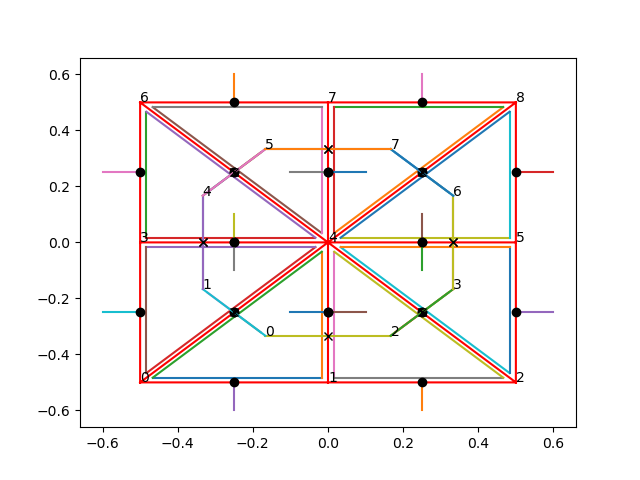

In [21]:
V, T = make_beam_mesh(1.0,1.0,(2,2))

info = MeshInfo(V,T)

fig = plt.figure()
plt.triplot(info.V[:,0],info.V[:,1],info.T,color='r')
for v in range(len(V)):
    print('vertex ',v , ' has triangle neighbors ',info.get_triangles_of_vertex(v))
    plt.text(info.V[v,0],info.V[v,1], str(v))
for t in range(len(T)):
    print('Triangle ',t , ' has triangle neighbors ',info.get_triangles_of_triangle(t))
    c = info.get_triangle_center(t)
    plt.text(c[0],c[1], str(t))
for v in range(len(V)):
    print('vertex ',v , ' has vertex neighbors ',info.get_vertices_of_vertex(v))
for t in range(len(T)):
    c = info.get_triangle_center(t)
    for e in range(3):
        u, m = info.get_edge_vector_of_triangle(t,e)
        v = m - 0.5*u
        w = m + 0.5*u
        m = (m-c)*0.9 + c
        v = (v-c)*0.9 + c
        w = (w-c)*0.9 + c
        plt.plot([v[0], w[0]], [v[1], w[1]] )
for t in range(len(T)):
    for e in range(3):
        n, m = info.get_outward_normal_of_triangle(t,e)
        plt.plot([m[0], 0.1*n[0]+m[0]], [m[1], 0.1*n[1]+m[1]] )
        plt.plot(m[0], m[1],'ko')
for t in range(len(T)):
    for e in range(3):
        u, m = info.get_triangle_triangle_segment(t,e)
        if not u is None: 
            v = m - 0.5*u
            w = m + 0.5*u
            plt.plot([v[0], w[0]], [v[1], w[1]] )
            plt.plot(m[0], m[1],'kx')
plt.show()    

In [22]:
def get_cyclic_permuation(v, triangle):
    i = triangle[0]
    j = triangle[1]
    k = triangle[2]
    if i==v:
        return [i, j, k]
    if j==v:
        return [j, k, i]
    if k==v:
        return [k, i, j]
    return [-1, -1, -1]


def get_ccw_triangle_order(v, T):
    for t in range(len(T)):
        T[t,:] = get_cyclic_permuation(v, T[t,:])    
    if len(T) == 1:
        ccw_order = np.array([0], dtype=np.int64).flatten()
    else:
        ccw_order = []
        next_order = -np.ones( (len(T), ), dtype=np.int64 )
        prev_order = -np.ones( (len(T), ), dtype=np.int64 )
        for s in range(len(T)):
            A = T[s,:]
            for t in range(len(T)):
                B = T[t,:]
                if A[2]==B[1]:
                    next_order[s] = t
                if A[1]==B[2]:
                    prev_order[s] = t
        if np.any(prev_order<0):
            i = np.where(prev_order<0)[0]
            while i>=0:
                ccw_order.append(i)
                i = next_order[i]
        else:
            i = 0
            ccw_order.append(i)
            i = next_order[i]
            while i>0:
                ccw_order.append(i)
                i = next_order[i]            
        ccw_order = np.array(ccw_order, dtype=np.int64).flatten()
    return ccw_order
    
    
class VertexControlVolume:

    def __init__(self, v, info):
        self.v = v
        self.c = info.V[v,:].flatten()
        self.labels = info.get_triangles_of_vertex(v)
        K = len(self.labels)        
        self.K = K
        self.boundary = info.is_boundary_vertex(v)
        
        T = info.T[self.labels,:]
        for t in range(len(T)):
            T[t,:] = get_cyclic_permuation(v, T[t,:])    
        
        self.Lij = np.zeros(( K, ), dtype=np.float64 )
        self.Lik = np.zeros(( K, ), dtype=np.float64 )
        self.Nij = np.zeros(( K, 2), dtype=np.float64 )
        self.Nik = np.zeros(( K, 2), dtype=np.float64 )
        self.Sij = np.zeros(( K, 2), dtype=np.float64 )
        self.Sik = np.zeros(( K, 2), dtype=np.float64 )
        self.P = np.zeros(( K, 2), dtype=np.float64 )
        self.A = np.sum(info.A[self.labels])/3.0
        
        for e in range(K):
            i = T[e,0]
            j = T[e,1]
            k = T[e,2]
            
            pi = info.V[i,:]
            pj = info.V[j,:]
            pk = info.V[k,:]
            
            Eij = (pj-pi)
            Lij = np.linalg.norm(Eij)
            Nij = -hat(Eij)/Lij
            
            Eik = (pk-pi)
            Lik = np.linalg.norm(Eik)
            Nik = hat(Eik)/Lik
        
            self.Lij[e] = Lij/2
            self.Lik[e] = Lik/2
            self.Nij[e,:] = Nij
            self.Nik[e,:] = Nik
            self.Sij[e,:] = Eij/2
            self.Sik[e,:] = Eik/2
            self.P[e,:] = (pi+pj+pk)/3

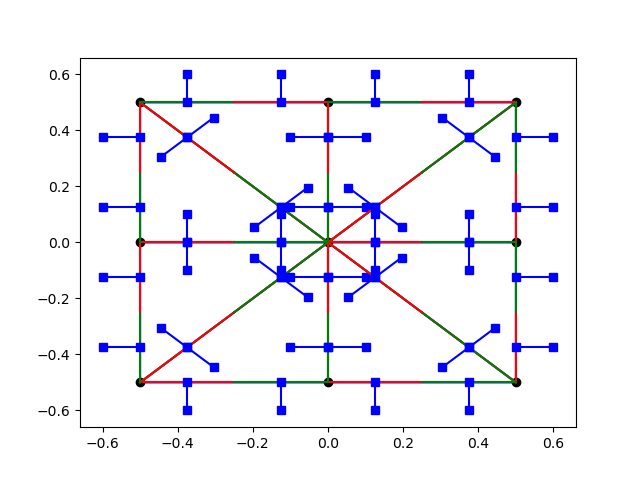

In [23]:
info = MeshInfo(V,T)

CVs = []
for v in range(len(V)):
    cv = VertexControlVolume(v,info)
    CVs.append(cv)            

fig = plt.figure()
plt.triplot(info.V[:,0],info.V[:,1],info.T,color='b')
for v in range(len(info.V)):
    cv = CVs[v]
    plt.plot(cv.c[0],cv.c[1],'ko')
    
    for e in range(cv.K):
        start = cv.c
        end = cv.c + cv.Sij[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-r')
                   
        start = cv.c
        end = cv.c + cv.Sik[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-g')

        start = cv.c+cv.Sij[e]/2
        end = cv.c+cv.Sij[e]/2 + cv.Nij[e]*0.1
        plt.plot([start[0], end[0]],[start[1], end[1]],'-bs')
                   
        start = cv.c+cv.Sik[e]/2
        end = cv.c+cv.Sik[e]/2 + cv.Nik[e]*0.1
        plt.plot([start[0], end[0]],[start[1], end[1]],'-bs')
plt.show()    

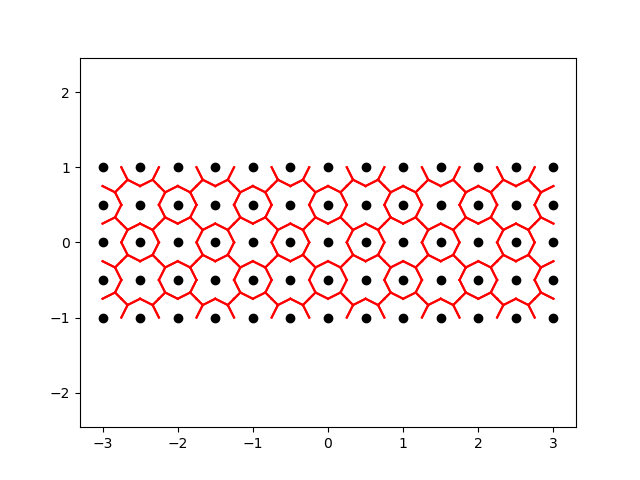

In [24]:
V, T = make_beam_mesh(6.0,2.0,(12,4))

info = MeshInfo(V,T)

CVs = []
for v in range(len(V)):
    cv = VertexControlVolume(v,info)
    CVs.append(cv)

fig = plt.figure()
ax = plt.subplot(111)
for v in range(len(CVs)):
    cv = CVs[v]
    plt.plot(cv.c[0],cv.c[1],'ko')
    for e in range(cv.K):
        start = cv.c + cv.Sij[e]
        end = cv.P[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-r')
        start = cv.c + cv.Sik[e]
        end = cv.P[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-r')
ax.axis('equal')
plt.show()

In [25]:
class Parameters:
    def __init__(self, material='default'):
        library = { 'cartilage':(0.69e6, 0.018, 1000),
               'cortical bone': (16.16e9, 0.33, 1600),
               'cancellous bone': (452e6, 0.3, 1600),
               'rubber': (0.01e9, 0.48, 1050),
               'concrete': (30e9, 0.20, 2320),
               'copper': (125e9, 0.35, 8900),
               'steel': (210e9, 0.31, 7800),
               'aluminium': (72e9, 0.34, 2700),
               'glass': ( 50e9,  0.18, 2190),
               'default': (10e5,0.3,1000)}
        E, nu, rho = library[material]
        self.E = E              # Young Modulus
        self.nu = nu            # Poisson ratio
        self.rho = rho          # Mass density
        self.lambda_ =  (E*nu) / ((1+nu)*(1-2*nu))  # Lame 1st
        self.mu_     =  E/(2*(1+nu))                # Lame 2nd

In [26]:
def get_edge_vertices(V,edge = 'right'):
    """
    Returns the indices of the vertices that are on the specified edge of the mesh.

    Parameters:
        V(np.ndarray):
            The vertices of the mesh, shape (N, 2) where N is the number of vertices.
        edge(str):
            The edge to check, can be 'right', 'left', 'top', or 'bottom'.

    Returns:
        np.ndarray:
            Indices of the vertices that are on the specified edge.
    """
    if edge == 'right':
        x_max = np.max(V[:,0])
        return np.where(V[:,0] == x_max)[0]
    elif edge == 'left':
        x_min = np.min(V[:,0])
        return np.where(V[:,0] == x_min)[0]
    elif edge == 'top':
        y_max = np.max(V[:,1])
        return np.where(V[:,1] == y_max)[0]
    elif edge == 'bottom':
        y_min = np.min(V[:,1])
        return np.where(V[:,1] == y_min)[0]

In [27]:
class Simulator():
    def __init__(self,V,T,material='default'):
        """
        Initialize the simulator with the mesh vertices, triangles, and material properties.
        Parameters:
            V(np.ndarray): Vertices of the mesh, shape (N, 2) where N is the number of vertices.
            T(np.ndarray): Triangles of the mesh, shape (M, 3) where M is the number of triangles.
            material(str): Material name from the predefined library or 'default'.
        """
        self.T = T
        self.init_V = V
        self.curr_V = self.init_V.copy()
        self.init_info = MeshInfo(V,T)
        self.curr_info = MeshInfo(self.curr_V,T)
        self.init_CVs = self._create_init_cvs()
        self.velocities = np.zeros(V.shape,dtype=np.float64)
        self.material = Parameters(material)
        
        self.curr_elastics = np.zeros((len(self.init_V),2),dtype=np.float64)
        self.curr_externals = np.zeros((len(self.init_V),2),dtype=np.float64)
        self.curr_tractions = np.zeros((len(self.init_V),2),dtype=np.float64)

        self.stages = []

    def _create_init_cvs(self):
        """
        Create initial control volumes for each vertex in the mesh.
        """
        self.init_CVs = []
        for v in range(len(self.init_V)):
            cv = VertexControlVolume(v,self.init_info)
            self.init_CVs.append(cv)
        return self.init_CVs

    def _calc_1st_PK_stress(self):
        Pes = []
        # Iterate over tirangles
        for iter in range (len(self.T)):
            t = self.T[iter]
            p_I,p_J,p_K = self.init_V[t]
            p_i,p_j,p_k = self.curr_V[t]
            # compute Gji and Gkj
            Gji = p_J - p_I
            Gkj = p_J - p_K
            # compute gji and gkj
            gji = p_j - p_i 
            gkj = p_j - p_k
            #
            De0 = np.stack([Gji, Gkj]).T
            De = np.stack([gji, gkj]).T
            # Deformation gradient
            #Fe = De @ np.linalg.inv(De0)
            Fe = np.matmul(De,np.linalg.inv(De0))
            # Green strain tensor
            Ee = 0.5 * ((np.matmul(Fe.T, Fe)) - np.eye(2))
            # 2nd Piola-Kirchhoff stress tensor
            Se = self.material.lambda_ * np.trace(Ee) * np.eye(2) + (2 * self.material.mu_ * Ee)
            # 1st Piola-Kirchhoff stress tensor
            Pe = Fe @ Se
            Pes.append(Pe)

        return Pes
    
    def _is_on_line(self, vertex, line):
        """
        Check if a vertex is on a given line.

        Parameters:
            vertex(np.ndarray): The vertex to check, shape (2,).
            line(np.ndarray): The line defined by two points, shape (2, 2).

        Returns:
            bool: True if the vertex is on the line, False otherwise.
        """
        p1, p2 = line
        # Check if the vertex is between the two points of the line
        return np.all(np.logical_and(np.minimum(p1, p2) <= vertex, vertex <= np.maximum(p1, p2)))

    def _find_traction_vertices(self, V, traction_line):
        """
        Find vertices that are on the traction line.

        Parameters:
            V(np.ndarray): The vertices of the mesh, shape (N, 2).
            traction_line(np.ndarray): The line segment defined by two points, shape (2, 2).

        Returns:
            list: Indices of vertices that are on the traction line.
        """
        traction_vertices = []
        for i, vertex in enumerate(V):
            if self._is_on_line(vertex, traction_line):
                traction_vertices.append(i)
        return traction_vertices

    def _ortho_vec(self, line):
        """
        Calculate the orthogonal line to a given line segment.

        Parameters:
            line(np.ndarray): The line segment defined by two points, shape (2, 2).

        Returns:
            np.ndarray: The orthogonal line segment.
        """
        p1, p2 = line
        v = p2 - p1
        v = v / np.linalg.norm(v)  
        return np.array([-v[1], v[0]])
        
    def _init_traction_info(self, V_info, traction_line):
        """
        Initialize traction information for vertices that are on the traction line.
        Parameters:
            V_info(MeshInfo): Mesh information containing vertices and triangles.
            traction_line(np.ndarray): The line segment defining the traction line, shape (2, 2).
        Returns:
            dict: A dictionary where keys are vertex indices and values are lists of tuples containing triangle 
                index and whether the edge is traction edge.
        """
        # for each vertex
        traction_info = {}
        tract_ortho = self._ortho_vec(traction_line)
        tract_ortho = abs(tract_ortho)  # Use absolute values to avoid direction issues
        for i in self.traction_vertices:
            cv = VertexControlVolume(i,V_info)
            # for each neighbouring triangle
            for j in range(len(cv.labels)):
                # check if either edge is orthogonal to the traction line
                # and will be traction edge
                Nij = abs(cv.Nij[j])
                Nik = abs(cv.Nik[j])
                ij = int(np.equal(Nij, tract_ortho).all())
                ik = int(np.equal(Nik, tract_ortho).all())
                if not i in traction_info:
                    traction_info[i] = []
                # foe each verted strore (triangle index, if use ij, if use ik)
                traction_info[i].append((j, ij, ik))
        return traction_info

    def _go_step(self,t_delta:float,traction_mass:np.ndarray,gravitation:np.ndarray):
        """
        Perform a single simulation step, updating the mesh vertices based on the forces acting on them.
        Parameters:
            t_delta(float): Time step for the simulation.
            traction_mass(np.ndarray): Mass of the traction vertices, shape (2,).
            gravitation(np.ndarray): Gravitational force applied to the mesh, shape (2,).
        """
        Pes = self._calc_1st_PK_stress()
        # for each node
        for i in range(len(V)):
            if i in self.constant_nodes: continue
            # initial CV
            cv_init = self.init_CVs[i]
            # current CV
            cv = VertexControlVolume(i,self.curr_info)
            # elastic forces
            elastic_F = np.zeros((2,),dtype=np.float64)
            # traction forces
            traction_F = np.zeros((2,),dtype=np.float64)
            # exterior forces
            external_F = np.zeros((2,),dtype=np.float64)
            # for each neighbouring triangle
            for j in range(len(cv.labels)):
                t = cv.labels[j]
                pe = Pes[t]
                Nij = cv_init.Nij[j]
                Nik = cv_init.Nik[j]
                Lij = cv.Lij[j]
                Lik = cv.Lik[j]
                # elastic forces
                elastic_F -= (1/2 * (pe @ Nij) * (1/Lij) ) 
                elastic_F -= (1/2 * (pe @ Nik) * (1/Lik) )
                # exterior forces
                external_F += gravitation*cv.A
            # traction forces for traction vertices
            if i in self.traction_vertices:
                trac_info = self.traction_info[i]
                for j, ij, ik in trac_info:
                        Lij = cv.Lij[j]
                        traction_F += traction_mass * Lij * ij
                        Lik = cv.Lik[j]
                        traction_F += traction_mass * Lik * ik
            
            self.curr_elastics[i] = elastic_F
            self.curr_externals[i] = external_F
            self.curr_tractions[i] = traction_F

            f = elastic_F + traction_F + external_F
            mass = cv.A * self.material.rho
            self.velocities[i] += (f * t_delta * (1/mass))
            self.curr_V[i] = (cv.c + (t_delta * self.velocities[i]))
    
    def _log_stage(self):
        """
        Log the current state of the simulation, including vertices, triangles, velocities, and forces.
        This state can be used for visualization or debugging purposes.
        """
        stage = {
            'vertices': self.curr_V.copy(),
            'triangles': self.T,
            'velocities': self.velocities.copy(),
            'elastics': self.curr_elastics.copy(),
            'externals': self.curr_externals.copy(),
            'tractions': self.curr_tractions.copy(),
        }
        self.stages.append(stage)

    def simulate(self,
                 iterations : int,
                 t_delta : float,
                 traction_force : np.ndarray,
                 gravitation :np.ndarray,
                 constant_nodes : list,
                 traction_line : np.ndarray,
                 log_intermittent_stages : bool =True
                ):
        """
        Simulate the mesh deformation over a number of iterations.
        Parameters:
            iterations(int): Number of simulation iterations.
            t_delta(float): Time step for the simulation.
            traction_force(np.ndarray): Force applied at the traction vertices.
            gravitation(np.ndarray): Gravitational force applied to the mesh.
            constant_nodes(list): List of indices of nodes that should not move.
            traction_line(np.ndarray): Line segment defining the traction line.
        """
        self.constant_nodes = constant_nodes
        self.traction_line = traction_line
        self.traction_vertices = self._find_traction_vertices(V,self.traction_line)
        self.traction_info = self._init_traction_info(self.init_info,self.traction_line)

        self._log_stage()
        for i in range(iterations):
            self._go_step(t_delta,traction_force,gravitation)
            self.curr_info = MeshInfo(self.curr_V,T)
            self.last_sucessful_iteration = i+1
            # log the current state
            if (i+1) == iterations or log_intermittent_stages:
                self._log_stage()
        
            
        

In [28]:
V, T = make_beam_mesh(6.0,2.0,(12,4))
material = Parameters()

traction_force = np.array([0,-10e4]) # Traction force applied to the right edge of the beam
# external forces
gravitation = np.array([0,0])
# time change
t_delta = 10e-4
# Fixed nodes
fixed_nodes = get_edge_vertices(V, 'left')
# Vertices located on the traction line will be affected by the traction force
traction_line = np.array([[3, -1], [3, 1]], dtype=np.float64)


In [29]:

try:
   simulator = Simulator(V,T,'default')
except Exception as e:
    print(f"Initialization failed: {e}")

try:
    simulator.simulate(
                    iterations = 150,
                    t_delta = t_delta,
                    traction_force = traction_force,
                    gravitation = gravitation,
                    constant_nodes = fixed_nodes,
                    traction_line= traction_line,
                    )
except Exception as e:
    print('-'*40 + '\n'+ f" !!! Simulation failed: {e} !!!")
    print('last sucessful iteration: ', simulator.last_sucessful_iteration)

In [30]:
def plot_stage(stage,axis):
    """
    Plot the mesh stage with vertices, triangles, forces, and fixed vertices.
    Parameters:
        stage(dict): A dictionary containing the mesh stage data.
        axis(matplotlib.axes.Axes): The axes on which to plot the mesh.
    """
    V_stage = stage['vertices']
    T_stage = stage['triangles']
    # Plot the mesh
    axis.triplot(V_stage[:,0],V_stage[:,1],T_stage)
    # Plot traction, elastic and external forces
    axis.quiver(V_stage[:,0], V_stage[:,1],
                stage['tractions'][:,0], stage['tractions'][:,1],
                color='red',alpha=0.5, label='traction forces')
    axis.quiver(V_stage[:,0], V_stage[:,1],
                stage['elastics'][:,0],
                stage['elastics'][:,1],
                color='green',alpha=0.5, label='elastic forces')
    axis.quiver(V_stage[:,0], V_stage[:,1],
                stage['externals'][:,0], stage['externals'][:,1],
                color='blue',alpha=0.5, label='external forces')
    # Plot fixed vertices
    fixed_vertices = V_stage[simulator.constant_nodes]
    axis.scatter(fixed_vertices[:,0],fixed_vertices[:,1],
                 color='black',label='fixed vertices')
    # Plot traction vertices
    traction_vertices = V_stage[simulator.traction_vertices]
    axis.scatter(traction_vertices[:,0],traction_vertices[:,1],
                 color='red',label='traction vertices')


c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\matplotlib\quiver.py:651: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\matplotlib\quiver.py:651: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


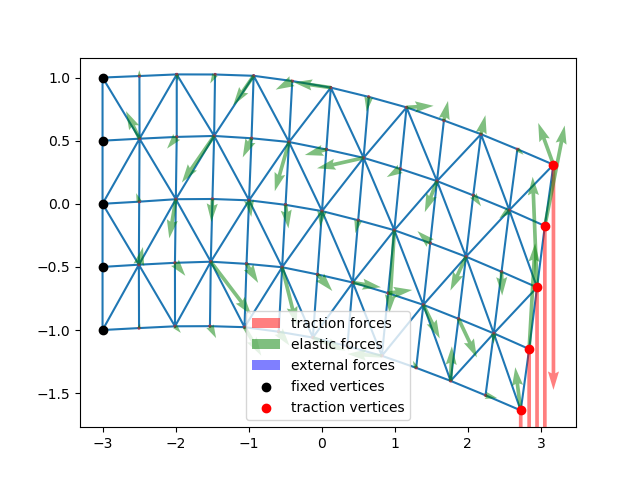

In [31]:
fig = plt.figure()
ax = plt.subplot(111)
last_stage = simulator.stages[-1]
plot_stage(last_stage,ax)
plt.legend()
plt.show()

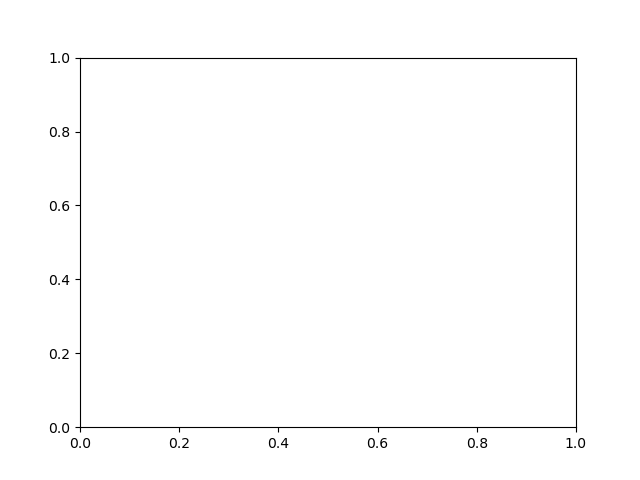

In [32]:


def mk_animation(stages, frames = 500, interval=250):
    # creating a blank window
    # for the animation 
    fig = plt.figure() 
    axis = plt.subplot(111)#, projection='3d') 
    def init(): 
        plot_stage(stages[0],axis)
        return axis
    
    # animation function 
    def animate(i): 
        axis.clear()
        j = i % len(stages)
        stage = stages[j]
        plot_stage(stage,axis)
        # make title
        axis.set_title(f'Iteration {j+1}/{len(stages)}')
        return axis
    # calling the animation function     
    anim = animation.FuncAnimation(fig, animate, init_func = init, frames = frames, interval = interval)
    return anim
    #anim.pause()

anim = mk_animation(simulator.stages, frames=500, interval=250)
plt.show()



In [33]:
# To stop the animation
plt.clf()
plt.close(fig)

In [34]:
# Run to save the animation as a gif
anim.save('beam_simulation.gif', writer='pillow', fps=10)